# Filtrado de señales con ruido de alta frecuencia: DSP clásico y Deep Learning

**Unidad — Procesamiento de Señales · Práctica de laboratorio**

Esta práctica muestra una secuencia de tres casos:

1. **Caso 1 — DSP clásico.** Una señal donde el ruido está *separado en frecuencia*. Diseñamos y comparamos un filtro **FIR** y uno **IIR**. Objetivo: ver el enfoque clásico funcionando y entender el trade-off FIR vs IIR.
2. **Caso 2 — DSP clásico vs Deep Learning (ECG).** Un caso donde el ruido *se solapa en frecuencia* con la señal (EMG sobre el complejo QRS). El filtro clásico no puede, y una **CNN 1D** entrenada con pares (ruidoso, limpio) gana.
3. **Caso 3 — Noise2Noise.** La respuesta moderna a la pregunta *"¿de dónde saco la señal limpia en un caso real?"*: entrenamos **sin dataset limpio**, usando dos observaciones ruidosas independientes de la misma señal.


In [3]:
# --- Dependencias ---
# neurokit2 se usa solo en los Casos 2 y 3 (ECG sintético). En Colab:
!pip install neurokit2 -q

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import neurokit2 as nk
import torch
import torch.nn as nn
import pandas as pd
import time

# Fijamos las semillas de numpy y de torch.
SEED = 42
rng = np.random.default_rng(SEED)   # generador de numpy para todo el ruido
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)
plt.rcParams["figure.figsize"] = (11, 3.2)


Dispositivo: cuda


In [4]:
# --- Funciones auxiliares que usaremos en toda la práctica ---

def snr_db(clean, est):
    """Relación señal-ruido en dB, tomando 'clean' como referencia (ground truth).
    Mide cuánta energía de la señal limpia sobrevive frente al error residual.
    Cuanto más alto, mejor."""
    clean = np.asarray(clean); est = np.asarray(est)
    error = clean - est
    return 10 * np.log10(np.sum(clean**2) / (np.sum(error**2) + 1e-12))

def plot_time(sigs, fs, title, xlim=None):
    """Grafica una o varias señales en el dominio del tiempo.
    'sigs' es una lista de tuplas (etiqueta, señal)."""
    t = np.arange(len(sigs[0][1])) / fs
    plt.figure()
    for label, x in sigs:
        plt.plot(t, x, label=label, alpha=0.85, lw=1.1)
    plt.xlabel("Tiempo [s]"); plt.ylabel("Amplitud"); plt.title(title)
    if xlim: plt.xlim(xlim)
    plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

def plot_spectrum(sigs, fs, title, fmax=None):
    """Grafica el espectro de magnitud (FFT) de una o varias señales.
    Permite visualizar dónde vive la señal y dónde vive el ruido en frecuencia."""
    plt.figure()
    for label, x in sigs:
        X = np.abs(np.fft.rfft(x)) / len(x)
        f = np.fft.rfftfreq(len(x), d=1/fs)
        plt.plot(f, X, label=label, alpha=0.85, lw=1.1)
    plt.xlabel("Frecuencia [Hz]"); plt.ylabel("|X(f)|"); plt.title(title)
    if fmax: plt.xlim(0, fmax)
    plt.legend(loc="upper right"); plt.tight_layout(); plt.show()


## Caso 1 — DSP clásico: cuando el ruido está separado en frecuencia

Generamos una señal compuesta por senoides de **baja frecuencia** (5, 12 y 20 Hz) y le sumamos:
- ruido de **alta frecuencia** (180 Hz + ruido blanco),
- una interferencia de **línea eléctrica** (50 Hz).

Como la señal vive en frecuencias bajas y el ruido en altas, un **pasa-bajos** los separa limpiamente. Vamos a diseñar dos: un **FIR** (`firwin`) y un **IIR** Butterworth (`butter`), y a compararlos.


In [5]:
# --- Generación de la señal del Caso 1 ---
fs1 = 1000                      # frecuencia de muestreo [Hz]
T = 2.0                         # duración [s]
t1 = np.arange(int(fs1*T)) / fs1

# Señal limpia: suma de tres senoides de baja frecuencia (la tomamos como ground truth)
clean1 = (np.sin(2*np.pi*5*t1)
          + 0.5*np.sin(2*np.pi*12*t1)
          + 0.3*np.sin(2*np.pi*20*t1))

# Ruido: alta frecuencia (180 Hz) + ruido blanco + interferencia de 50 Hz
hf_noise  = 0.8*np.sin(2*np.pi*180*t1) + 0.5*rng.standard_normal(t1.size)
line_50   = 0.4*np.sin(2*np.pi*50*t1)
noisy1    = clean1 + hf_noise + line_50

print(f"SNR de entrada (ruidosa vs limpia): {snr_db(clean1, noisy1):.2f} dB")


SNR de entrada (ruidosa vs limpia): 0.03 dB


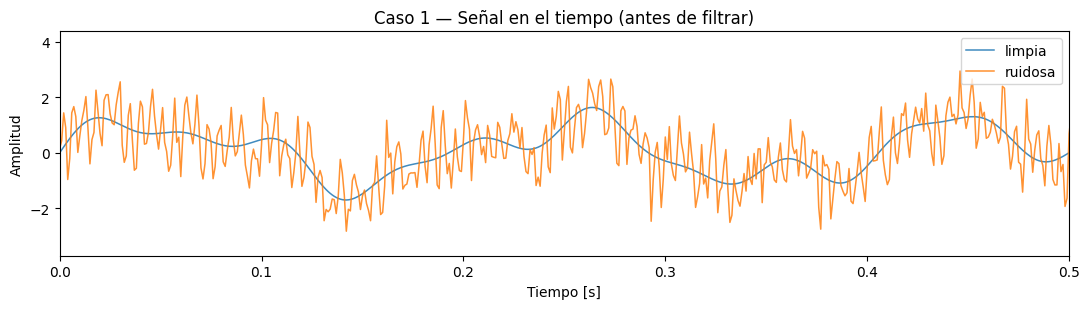

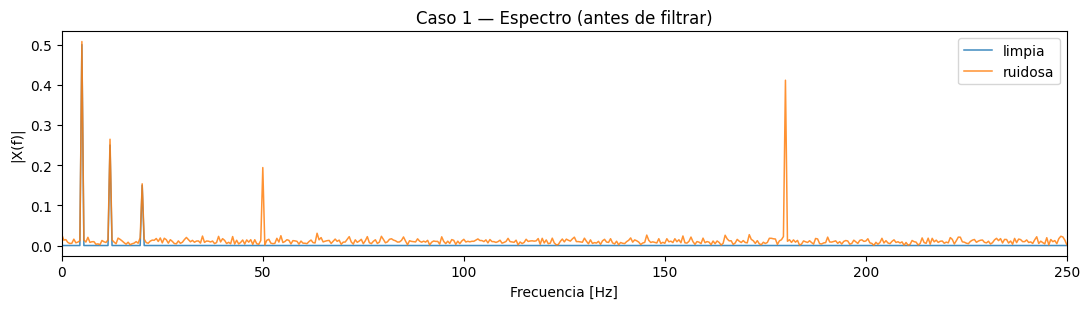

In [6]:
# --- Visualización ANTES de filtrar: tiempo y espectro ---
plot_time([("limpia", clean1), ("ruidosa", noisy1)], fs1,
          "Caso 1 — Señal en el tiempo (antes de filtrar)", xlim=(0, 0.5))
plot_spectrum([("limpia", clean1), ("ruidosa", noisy1)], fs1,
              "Caso 1 — Espectro (antes de filtrar)", fmax=250)
# En el espectro se ve clarísimo: la señal está en <20 Hz y el ruido en 50 y 180 Hz.


In [7]:
# --- Filtro FIR pasa-bajos (método de ventana) ---
fc = 30                                   # frecuencia de corte [Hz]
numtaps = 201                             # orden del FIR (cantidad de coeficientes)
b_fir = signal.firwin(numtaps, fc/(fs1/2))   # diseño; Wn normalizada a Nyquist (fs/2)
# filtfilt aplica el filtro hacia adelante y atrás -> fase cero (no corre la señal)
y_fir = signal.filtfilt(b_fir, [1.0], noisy1)
print(f"FIR: {numtaps} coeficientes | SNR salida = {snr_db(clean1, y_fir):.2f} dB")


FIR: 201 coeficientes | SNR salida = 16.64 dB


In [8]:
# --- Filtro IIR Butterworth pasa-bajos ---
order = 6
b_iir, a_iir = signal.butter(order, fc/(fs1/2), btype='low')
y_iir = signal.filtfilt(b_iir, a_iir, noisy1)   # filtfilt también cancela la fase del IIR
print(f"IIR Butterworth: orden {order} | SNR salida = {snr_db(clean1, y_iir):.2f} dB")


IIR Butterworth: orden 6 | SNR salida = 16.56 dB


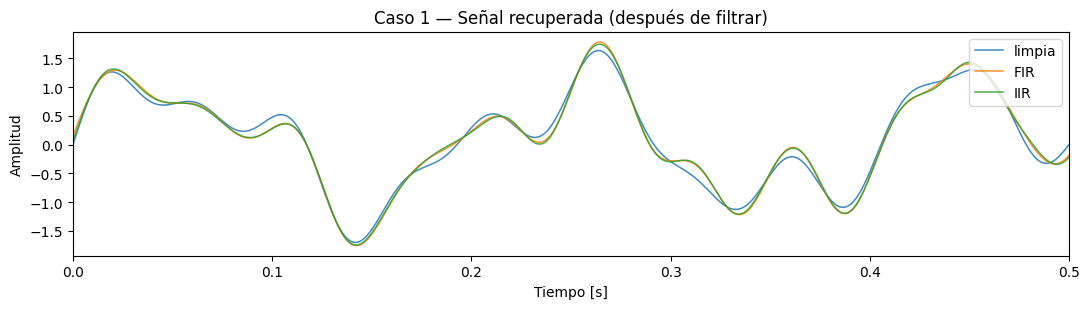

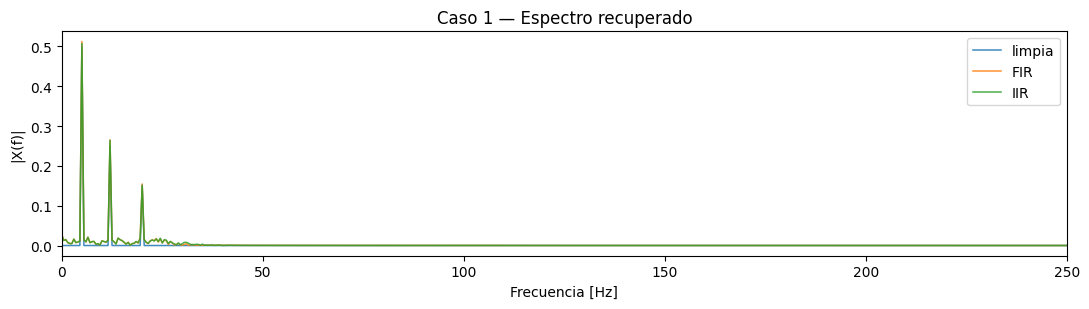

,Método,Complejidad,SNR salida [dB]
0,Entrada (ruidosa),-,0.03
1,FIR (firwin),201 coef.,16.64
2,IIR (Butterworth),orden 6,16.56


In [9]:
# --- Visualización DESPUÉS de filtrar + comparativa FIR vs IIR ---
plot_time([("limpia", clean1), ("FIR", y_fir), ("IIR", y_iir)], fs1,
          "Caso 1 — Señal recuperada (después de filtrar)", xlim=(0, 0.5))
plot_spectrum([("limpia", clean1), ("FIR", y_fir), ("IIR", y_iir)], fs1,
              "Caso 1 — Espectro recuperado", fmax=250)

tabla1 = pd.DataFrame({
    "Método":       ["Entrada (ruidosa)", "FIR (firwin)", "IIR (Butterworth)"],
    "Complejidad":  ["-", f"{numtaps} coef.", f"orden {order}"],
    "SNR salida [dB]": [round(snr_db(clean1, noisy1),2),
                        round(snr_db(clean1, y_fir),2),
                        round(snr_db(clean1, y_iir),2)],
})
tabla1


**Conclusión del Caso 1.** Cuando el ruido está separado en frecuencia, el DSP clásico resuelve el problema de forma simple, interpretable y barata. FIR e IIR logran un SNR similar; el IIR lo hace con muchos menos coeficientes (más eficiente), mientras que el FIR ofrece fase lineal exacta. **No hay que entrenar nada.** Este es el escenario donde el enfoque clásico es la elección correcta.


## Caso 2 — DSP clásico vs Deep Learning: ECG con ruido *in-band*

Ahora un caso donde el clásico **falla**. Usamos un **ECG** sintético (con `neurokit2`), donde el complejo **QRS** (el pico del latido) es un transitorio de **banda ancha**, y sus componentes rápidos **se solapan en frecuencia** con el ruido muscular (**EMG**).

Consecuencia: si bajamos el corte del pasa-bajos para eliminar el EMG, **redondeamos el QRS**; si lo subimos para preservar el QRS, **dejamos pasar el EMG**. No existe una frecuencia de corte que gane. Una **CNN 1D**, en cambio, aprende a distinguir QRS de EMG por su **forma**, no por su banda.

Nota: acá disponemos del ECG limpio *porque es sintético*. En un caso real, conseguir ese "limpio" es justamente el problema difícil — lo abordamos en el Caso 3.


In [10]:
# --- Generación del ECG limpio y del modelo de ruido ---
fs = 250          # frecuencia de muestreo del ECG [Hz] (típico de Holter)
seg_len = 500     # longitud de cada segmento: 2 s

def make_ecg(duration_s, heart_rate, seed):
    """ECG sintético con neurokit2, normalizado a media 0 y desvío 1."""
    x = nk.ecg_simulate(duration=duration_s, sampling_rate=fs,
                        heart_rate=heart_rate, random_state=seed, method="simple")
    return (x - np.mean(x)) / (np.std(x) + 1e-8)
    # --- Fallback sin neurokit2 (descomentar si hiciera falta) ---
    # Se puede sintetizar un ECG a mano sumando gaussianas para las ondas P-QRS-T.

def add_noise(clean, rng):
    """Suma tres ruidos realistas de ECG. IMPORTANTE para el Caso 3:
    todas las componentes se sortean al azar en cada llamada, así dos llamadas
    dan realizaciones de ruido INDEPENDIENTES sobre la misma señal limpia."""
    n = clean.size; tt = np.arange(n)/fs
    # 1) Baseline wander: deriva lenta (~0.15-0.4 Hz), p. ej. por respiración
    bw = rng.uniform(0.3,0.8)*np.sin(2*np.pi*rng.uniform(0.15,0.4)*tt + rng.uniform(0,2*np.pi))
    # 2) Interferencia de línea eléctrica (50 Hz)
    pl = rng.uniform(0.1,0.25)*np.sin(2*np.pi*50*tt + rng.uniform(0,2*np.pi))
    # 3) EMG: ruido gaussiano pasa-altos (>20 Hz) -> SE SOLAPA con el QRS (in-band)
    sos = signal.butter(4, 20/(fs/2), btype='high', output='sos')
    emg = rng.uniform(0.15,0.35)*signal.sosfilt(sos, rng.standard_normal(n))
    return clean + bw + pl + emg


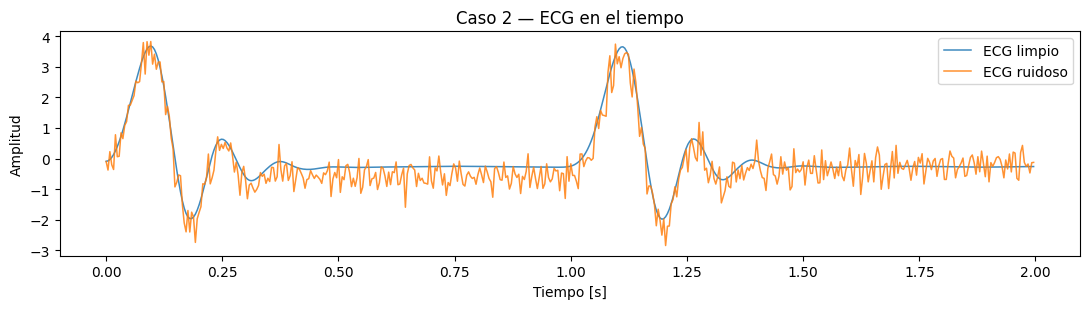

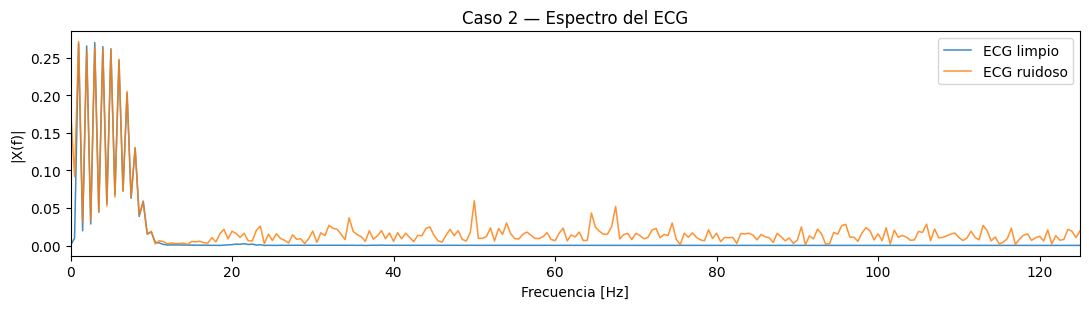

In [11]:
# --- Un ECG de ejemplo: limpio vs ruidoso, en tiempo y frecuencia ---
demo_clean = make_ecg(2.0, heart_rate=70, seed=7)
demo_noisy = add_noise(demo_clean, rng)

plot_time([("ECG limpio", demo_clean), ("ECG ruidoso", demo_noisy)], fs,
          "Caso 2 — ECG en el tiempo")
plot_spectrum([("ECG limpio", demo_clean), ("ECG ruidoso", demo_noisy)], fs,
              "Caso 2 — Espectro del ECG", fmax=125)
# En el espectro, el EMG no está en una banda aparte: se mezcla con la energía del QRS.


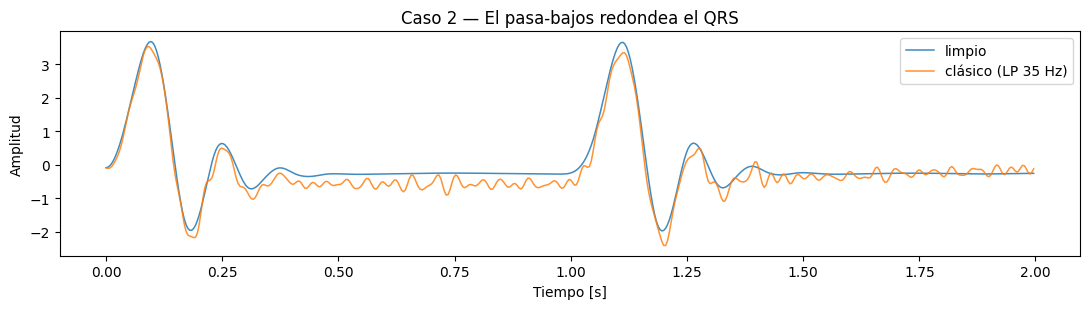

SNR entrada        : 8.00 dB
SNR clásico (LP35) : 12.03 dB


In [12]:
# --- Intento con DSP clásico: pasa-bajos para atacar el EMG ---
def classical_lowpass(x, fc):
    sos = signal.butter(4, fc/(fs/2), btype='low', output='sos')
    return signal.sosfiltfilt(sos, x)   # fase cero

cl_35 = classical_lowpass(demo_noisy, 35)   # corte agresivo para matar EMG

plot_time([("limpio", demo_clean), ("clásico (LP 35 Hz)", cl_35)], fs,
          "Caso 2 — El pasa-bajos redondea el QRS")
print(f"SNR entrada        : {snr_db(demo_clean, demo_noisy):.2f} dB")
print(f"SNR clásico (LP35) : {snr_db(demo_clean, cl_35):.2f} dB")
# El SNR mejora poco Y el pico QRS queda suavizado: no hay corte que gane.


In [13]:
# --- Dataset de entrenamiento supervisado: pares (ruidoso, limpio) ---
N = 60
clean_segs = []
for i in range(N):
    hr = int(rng.integers(55, 95))                    # variamos la frecuencia cardíaca
    rec = make_ecg(4.0, hr, seed=1000+i)
    s = int(rng.integers(0, rec.size - seg_len))       # ventana aleatoria de 2 s
    clean_segs.append(rec[s:s+seg_len])
clean_segs = np.stack(clean_segs)                      # (N, seg_len) -> ground truth
noisy_segs = np.stack([add_noise(c, rng) for c in clean_segs])  # versión ruidosa

# Split train / val / test (sin solapamiento)
ntr, nva = 42, 9
Xtr, Xva, Xte = noisy_segs[:ntr], noisy_segs[ntr:ntr+nva], noisy_segs[ntr+nva:]
Ytr, Yva, Yte = clean_segs[:ntr], clean_segs[ntr:ntr+nva], clean_segs[ntr+nva:]
print("Formas -> train:", Xtr.shape, "| val:", Xva.shape, "| test:", Xte.shape)


Formas -> train: (42, 500) | val: (9, 500) | test: (9, 500)


In [14]:
# --- Arquitectura: CNN 1D denoiser (fully-convolutional, conserva la longitud) ---
class Denoiser1D(nn.Module):
    """Red convolucional 1D chica. Mapea señal (1 canal) -> señal (1 canal)
    de la misma longitud. El padding conserva la dimensión temporal."""
    def __init__(self, ch=24, k=11):
        super().__init__()
        p = k // 2
        self.net = nn.Sequential(
            nn.Conv1d(1, ch, k, padding=p), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.Conv1d(ch, ch, k, padding=p), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.Conv1d(ch, ch, k, padding=p), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.Conv1d(ch, 1, k, padding=p))
    def forward(self, x):
        return self.net(x)

def to_tensor(a):
    """(N, L) -> tensor (N, 1, L) en float32."""
    return torch.tensor(a, dtype=torch.float32).unsqueeze(1).to(device)


Entrenamiento supervisado: 6.8 s


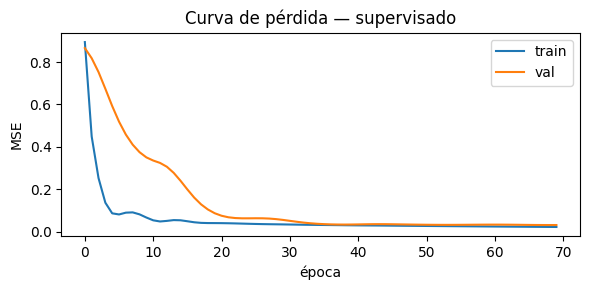

In [15]:
# --- Entrenamiento supervisado: la CNN aprende noisy -> clean ---
def train_denoiser(model, Xn, Yn, Xv, Yv, epochs=70, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.MSELoss()
    Xt, Yt = to_tensor(Xn), to_tensor(Yn)
    Xvt, Yvt = to_tensor(Xv), to_tensor(Yv)
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        loss = lossf(model(Xt), Yt); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist["train"].append(loss.item())
            hist["val"].append(lossf(model(Xvt), Yvt).item())
    return hist

torch.manual_seed(SEED)
sup_model = Denoiser1D()
t0 = time.time()
hist_sup = train_denoiser(sup_model, Xtr, Ytr, Xva, Yva)   # TARGET = limpio
print(f"Entrenamiento supervisado: {time.time()-t0:.1f} s")

plt.figure(figsize=(6,3))
plt.plot(hist_sup["train"], label="train"); plt.plot(hist_sup["val"], label="val")
plt.xlabel("época"); plt.ylabel("MSE"); plt.title("Curva de pérdida — supervisado")
plt.legend(); plt.tight_layout(); plt.show()


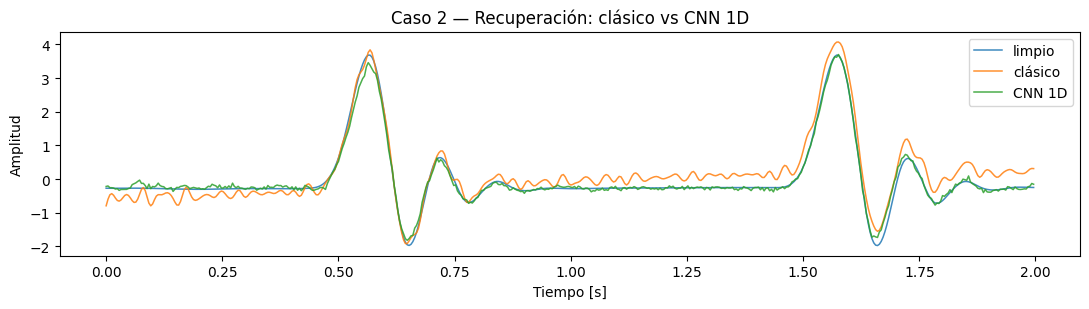

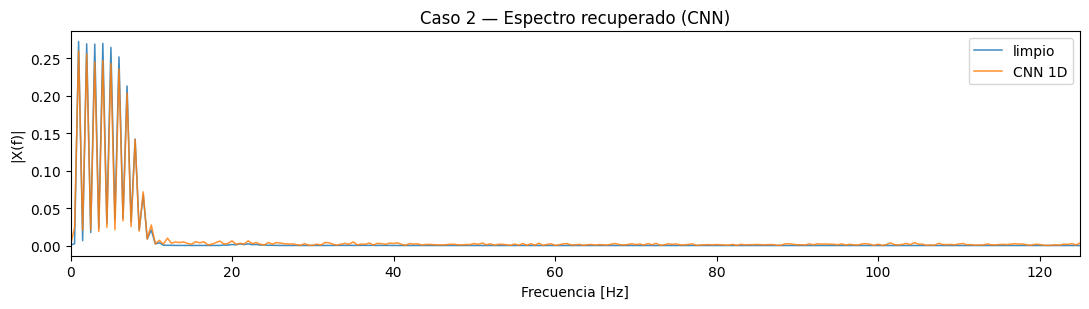

SNR clásico : 10.01 dB
SNR CNN 1D  : 19.22 dB


In [16]:
# --- Evaluación en una señal de test: clásico vs CNN supervisada ---
def denoise(model, x):
    model.eval()
    with torch.no_grad():
        return model(to_tensor(x[None])).squeeze().cpu().numpy()

x_test, y_test = Xte[0], Yte[0]
est_classical = classical_lowpass(x_test, 35)
est_sup = denoise(sup_model, x_test)

plot_time([("limpio", y_test), ("clásico", est_classical), ("CNN 1D", est_sup)], fs,
          "Caso 2 — Recuperación: clásico vs CNN 1D")
plot_spectrum([("limpio", y_test), ("CNN 1D", est_sup)], fs,
              "Caso 2 — Espectro recuperado (CNN)", fmax=125)
print(f"SNR clásico : {snr_db(y_test, est_classical):.2f} dB")
print(f"SNR CNN 1D  : {snr_db(y_test, est_sup):.2f} dB")


**Conclusión del Caso 2.** Cuando el ruido se solapa en frecuencia con la señal, el filtro clásico —que solo sabe de bandas— no puede separar sin dañar la señal. La CNN 1D aprende a discriminar por **forma** y recupera el QRS. El precio: necesitó **pares (ruidoso, limpio)** para entrenar. Y ahí aparece la pregunta del millón: *en un caso real, ¿de dónde sale el limpio?*


## Caso 3 — Noise2Noise: aprender a limpiar **sin ninguna señal limpia**

En la práctica casi nunca tenemos el limpio. **Noise2Noise** (Lehtinen et al., 2018) muestra algo sorprendente: se puede entrenar un denoiser usando **dos observaciones ruidosas independientes de la misma señal** — sin ver jamás el limpio. Bajo ruido de media cero, el óptimo al que converge la red es el mismo que con el limpio como objetivo.

**Cómo reusamos la data del Caso 2:** mismos ECG limpios, mismo modelo de ruido. Lo único que cambia es que generamos **dos** realizaciones ruidosas independientes (A y B) por señal, y entrenamos **A → B**. El limpio se guarda **solo para evaluar**, nunca entra al entrenamiento.

Lehtinen, J., Munkberg, J., Hasselgren, J., Laine, S., Karras, T., Aittala, M. & Aila, T. (2018). Noise2Noise: Learning Image Restoration without Clean Data. Proceedings of the 35th International Conference on Machine Learning (ICML), PMLR 80:2965-2974. Preprint en arXiv:1803.04189.


In [21]:
# --- Dataset Noise2Noise: dos realizaciones ruidosas independientes por señal ---
# Reusamos clean_segs y add_noise del Caso 2. Como add_noise sortea TODAS sus
# componentes (fase del baseline, fase del 50 Hz y el EMG) en cada llamada,
# noisyA y noisyB son ruido INDEPENDIENTE sobre el MISMO limpio.
noisyA = np.stack([add_noise(c, rng) for c in clean_segs])
noisyB = np.stack([add_noise(c, rng) for c in clean_segs])

Atr, Btr = noisyA[:ntr],           noisyB[:ntr]            # entrada A, objetivo B
Ava, Bva = noisyA[ntr:ntr+nva],    noisyB[ntr:ntr+nva]
# El limpio (Yte) y el test ruidoso (Xte) del Caso 2 se usan SOLO para evaluar.
print("N2N -> entrada:", Atr.shape, "| objetivo (otra ruidosa):", Btr.shape)


N2N -> entrada: (42, 500) | objetivo (otra ruidosa): (42, 500)


Entrenamiento N2N: 0.2 s  (nunca vio una señal limpia)


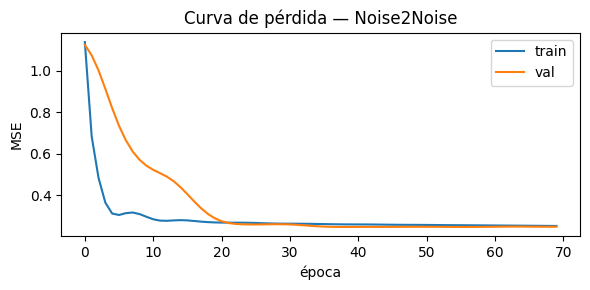

In [18]:
# --- Entrenamiento Noise2Noise: MISMA arquitectura, objetivo = otra ruidosa ---
torch.manual_seed(SEED)
n2n_model = Denoiser1D()
t0 = time.time()
hist_n2n = train_denoiser(n2n_model, Atr, Btr, Ava, Bva)   # TARGET = ruidosa B
print(f"Entrenamiento N2N: {time.time()-t0:.1f} s  (nunca vio una señal limpia)")

plt.figure(figsize=(6,3))
plt.plot(hist_n2n["train"], label="train"); plt.plot(hist_n2n["val"], label="val")
plt.xlabel("época"); plt.ylabel("MSE"); plt.title("Curva de pérdida — Noise2Noise")
plt.legend(); plt.tight_layout(); plt.show()
# Nota: el MSE no baja a cero (el objetivo es ruidoso), pero la red igual aprende la señal.


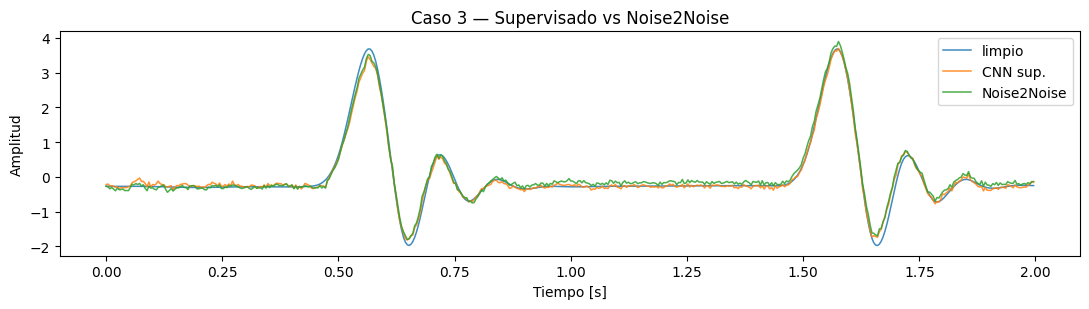

SNR CNN supervisada : 19.22 dB
SNR Noise2Noise     : 17.74 dB  <-- sin ver ningún limpio


In [19]:
# --- Evaluación N2N sobre el MISMO test ruidoso del Caso 2 ---
est_n2n = denoise(n2n_model, x_test)   # mismo x_test que usamos con clásico y supervisado

plot_time([("limpio", y_test), ("CNN sup.", est_sup), ("Noise2Noise", est_n2n)], fs,
          "Caso 3 — Supervisado vs Noise2Noise")
print(f"SNR CNN supervisada : {snr_db(y_test, est_sup):.2f} dB")
print(f"SNR Noise2Noise     : {snr_db(y_test, est_n2n):.2f} dB  <-- sin ver ningún limpio")


**El escalón siguiente (solo mención): Noise2Void / Noise2Self.** Cuando ni siquiera se tienen *dos* observaciones del mismo evento, estas técnicas aprenden de observaciones ruidosas **sueltas**, usando enmascaramiento de "blind spot" y el hecho de que la señal está correlacionada en el tiempo pero el ruido no. Son más delicadas de entrenar; quedan como lectura opcional.


In [20]:
# --- Tabla comparativa final sobre TODO el test set (mismo input Xte) ---
def mean_snr(est_fn):
    return float(np.mean([snr_db(Yte[i], est_fn(Xte[i])) for i in range(len(Xte))]))

snr_in   = mean_snr(lambda x: x)                          # sin filtrar
snr_cl   = mean_snr(lambda x: classical_lowpass(x, 35))    # clásico
snr_sup  = mean_snr(lambda x: denoise(sup_model, x))       # CNN supervisada
snr_n2n  = mean_snr(lambda x: denoise(n2n_model, x))       # Noise2Noise

resumen = pd.DataFrame({
    "Método": ["Sin filtrar", "DSP clásico (LP 35 Hz)",
               "CNN 1D supervisada", "Noise2Noise"],
    "Necesita limpio": ["-", "No", "Sí", "No"],
    "SNR medio [dB]": [round(snr_in,2), round(snr_cl,2),
                       round(snr_sup,2), round(snr_n2n,2)],
})
resumen


,Método,Necesita limpio,SNR medio [dB]
0,Sin filtrar,-,6.12
1,DSP clásico (LP 35 Hz),No,7.84
2,CNN 1D supervisada,Sí,17.27
3,Noise2Noise,No,16.00


## Discusión final

| Escenario | Ruido | Mejor enfoque | Por qué |
|---|---|---|---|
| Caso 1 | separado en frecuencia | **DSP clásico (FIR/IIR)** | separable por banda; simple, interpretable, sin datos |
| Caso 2 | solapado (in-band) | **CNN 1D supervisada** | discrimina por forma; requiere pares (ruidoso, limpio) |
| Caso 3 | solapado, sin limpio | **Noise2Noise** | aprende de dos vistas ruidosas; no necesita ground truth |

**Secuencia completa:** *diseñar* (Caso 1) → *aprender con ground truth* (Caso 2) → *aprender sin ground truth* (Caso 3).

**El punto que suele sorprender:** en un problema real de denoising, **conseguir los datos apareados es el 80% del trabajo**; la arquitectura es el 20%. Por eso importa conocer de dónde puede salir el "limpio": ruido sintético sobre señal buena, sensores apareados, promediado de repeticiones, referencia física redundante, o métodos self-supervised (Noise2Noise / Noise2Void) cuando no hay limpio de ninguna forma.
